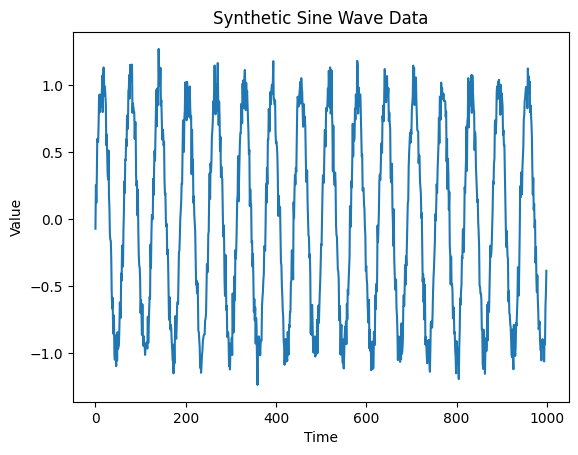

Epoch 1/50


C:\Users\abhis\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0902
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0273
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0246
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0211
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0186
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0132
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0111
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0088
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0066
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0071
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0060
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0067
Epoch 13/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0064
Epoch 14/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0055
Epoch 15/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0064
Epoch 16/50
25/25 ━━━━━━━━━━━

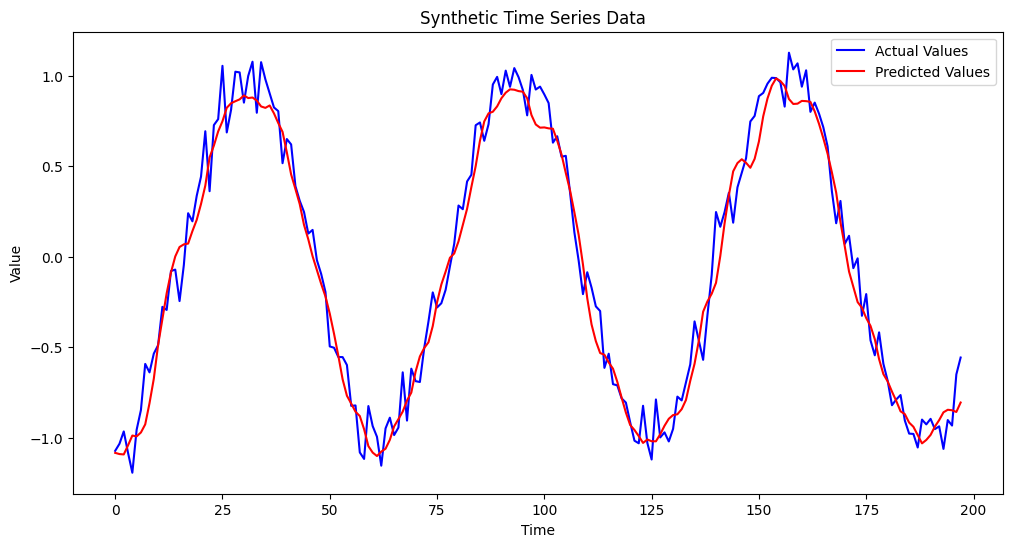

In [ ]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import MinMaxScaler 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import LSTM, Dense, Dropout 

def generate_sine_wave(seq_length=1000): 
    x = np.linspace(0, 100, seq_length) 
    y = np.sin(x) + np.random.normal(scale=0.1, size=seq_length) 
    return y 
data = generate_sine_wave() 
plt.plot(data) 
plt.title("Synthetic Sine Wave Data") 
plt.xlabel("Time") 
plt.ylabel("Value") 
plt.show() 

def create_dataset(data, time_step=1): 
    X, y = [], [] 
    for i in range(len(data) - time_step - 1): 
        X.append(data[i:(i + time_step)]) 
        y.append(data[i + time_step]) 
    return np.array(X), np.array(y) 

scaler = MinMaxScaler(feature_range=(0, 1)) 
data = scaler.fit_transform(data.reshape(-1, 1)) 
time_step = 10 
X, y = create_dataset(data, time_step) 
X = X.reshape(X.shape[0], X.shape[1], 1) 
train_size = int(len(X) * 0.8) 
X_train, X_test = X[:train_size], X[train_size:] 
y_train, y_test = y[:train_size], y[train_size:] 
model = Sequential() 
model.add(LSTM(50, return_sequences=True, input_shape=(X_train.shape[1], 1))) 
model.add(Dropout(0.2)) 
model.add(LSTM(50, return_sequences=False)) 
model.add(Dropout(0.2)) 
model.add(Dense(1)) 
model.compile(optimizer='adam', loss='mean_squared_error') 
model.fit(X_train, y_train, epochs=50, batch_size=32) 
train_predict = model.predict(X_train) 
test_predict = model.predict(X_test) 
train_predict = scaler.inverse_transform(train_predict) 
test_predict = scaler.inverse_transform(test_predict) 
y_train_actual = scaler.inverse_transform(y_train.reshape(-1, 1)) 
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)) 
plt.figure(figsize=(12, 6)) 
plt.plot(y_test_actual, label='Actual Values', color='blue') 
plt.plot(test_predict, label='Predicted Values', color='red') 
plt.title('Synthetic Time Series Data  ') 
plt.xlabel('Time') 
plt.ylabel('Value') 
plt.legend() 
plt.show()